## Week 2 - Assignment 2 for COfDSAI Tutorial Markdown ##

For this week, need to first interpret the requests of the board members.
First do all the importing and initialisation.

In [292]:
# necessary imports
import numpy as np
import cvxpy as cp
import matplotlib.pyplot as plt
from scipy.stats import norm
from load_industries import load_industry_returns, estimation_inputs

In [293]:
# want to run the load_industries.py file to get the needed data
R = load_industry_returns("30_Industry_Portfolios.csv")
mu, Sigma, names = estimation_inputs(R, start="2015-01", end="2024-12")

#print(mu, Sigma, names)


First we need to run the base case again so that we can compare to it.

In [294]:

# initialise for the base case 
n = len(mu)
weq = 1/n
weq_v = weq*np.ones(30)
#weq_v

sigma2 = weq_v.T @ Sigma @ weq_v
sigma2
volatilityeq = 100 * np.sqrt(weq_v @ Sigma @ weq_v)

print("The upper bound of our variance is:", sigma2*100, "%")
print("With a volatility of: ", volatilityeq, "%")

status = {}
def solve(problem, var, name):
    problem.solve()
    status[name] = problem.status
    if var.value is None:                        # infeasible / failed
        return None
    return np.clip(var.value, 0, None)

# --- base case: max return s.t. variance <= equal-weight variance -------
w = cp.Variable(n)
w_eq = np.ones(n) / n
base_cons = [cp.sum(w) == 1, w >= 0,
             cp.quad_form(w, Sigma) <= w_eq @ Sigma @ w_eq]
w_base = solve(cp.Problem(cp.Maximize(mu @ w), base_cons), w, "base")

# --- "good return" floor: at least 80% of the base-case return ----------
r_floor = 0.8 * (mu @ w_base)
USE_FLOOR = True



#  have n variables w
w = cp.Variable(n)
proba = cp.Problem(cp.Maximize(mu @ w),
                    [
                        cp.sum(w) == 1,
                        w >= 0,
                        cp.quad_form(w, Sigma) <= sigma2,
                    ])

proba.solve()

# get annual return and volatility (where volatility is the standard deviation)
returna = proba.value * 100
volatilitya = 100 * np.sqrt(wa @ Sigma @ wa)

# check if the solution is optimal
print("Status of solution: ", proba.status)
print("Expected Annual Return of Base Case Portfolio: ", returna, "%")
print("Annual Volatility of Base Case Portfolio: ", volatilitya, "%")

# look at the weights that were assigned to each stock in the portfolio
for i in range(n):
    if w.value[i] > 0.0001: # put a threshold, so if the weight of that stock is less than 0.0001 we ignore it
        print(names[i], round(100 * w.value[i], 2), "%") # print the weights of the invested stocks

The upper bound of our variance is: 3.0154289808169934 %
With a volatility of:  17.364990586858934 %
Status of solution:  optimal
Expected Annual Return of Base Case Portfolio:  19.232658942032668 %
Annual Volatility of Base Case Portfolio:  17.364990598603864 %
Smoke 14.4 %
Util 6.38 %
Servs 17.3 %
BusEq 60.35 %
Meals 1.57 %


# Implementation and comparison

I decided to implement the Chair's wish (using the Sharpe ratio) and the Risk manager's wish. 
I define the "good" return so that it can be compared to.

In [295]:
# first define the "good" return
rgood = 0.8 * (mu @ wa)
print("The \"Good\" Annual Return: ", rgood*100, "%")

The "Good" Annual Return:  15.38612715362614 %


Now implement the Sharpe ratio based convex problem (both the original and reformulated to see which works). We consider there to be no risk-free rate (from assignment).
The first formulation should fail as it isn't convex, and the reformulation should work.


In [296]:
# first initialise the variables needed for metrics and formulation
rf = 0
# slice R to the 10 year window (T = 120 months)
R_sample = R.loc["2015-01":"2024-12"]

# Check if returns are in decimals or percentages; convert to decimal if needed
R_mat = R_sample.values if hasattr(R_sample, "values") else np.asarray(R_sample)
if np.nanmean(np.abs(R_mat)) > 0.5:
  R_mat = R_mat / 100.0

T, n = R_mat.shape  # This will now be exactly (120, 30)
k = int(round(0.05 * T))  # Exactly 6 months
rf = 0
z = norm.ppf(0.95)

print(f"Data sliced: T = {T} months (2015-01 to 2024-12), k = {k} worst months")

wsncvx = cp.Variable(n)
probsncvx = cp.Problem(cp.Maximize((mu @ wsncvx - rf) / cp.sqrt(cp.quad_form(wsncvx, Sigma))),
                                [
                                    cp.sum(wsncvx) == 1,
                                    wsncvx >= 0,
                                    mu @ wsncvx >= rgood
                                ])

try:
    probsncvx.solve()
except cp.error.DCPError as e:
    print("Status of solution: Rejected by CVXPY")

probsncvx.is_dcp()

Data sliced: T = 120 months (2015-01 to 2024-12), k = 6 worst months
Status of solution: Rejected by CVXPY


False

Now we can do the reformulated version of the problem, and observe our returns.

In [297]:
# introduce the new decision variables for the reformulated Sharpe ratio
y = cp.Variable(n)
kappa = cp.Variable()

sharpe_cons = [mu @ y - rf * kappa == 1,         # risk normalisation
               cp.sum(y) == kappa,               # budget constraint in scaled form
               y >= 0, kappa >= 0]

if USE_FLOOR:
    # mu'w >= r_floor  <=>  mu'y >= r_floor * kappa   (linear in y, kappa)
    sharpe_cons.append(mu @ y >= rgood * kappa)
    
y_val = solve(cp.Problem(cp.Minimize(cp.quad_form(y, Sigma)), sharpe_cons), y, "sharpe")
w_sharpe = None if y_val is None else y_val / kappa.value


Now we can do the Risk manager's wish.

In [298]:
# introduce the variables needed for this implementation
wcvar = cp.Variable(n)
losses = -R_mat @ wcvar

cvar_cons = [
    cp.sum(wcvar) == 1,
    wcvar >= 0,
    cp.sum_largest(losses, k) / k <= 0.08,
]
if USE_FLOOR:
  cvar_cons.append(mu @ wcvar >= r_floor)

w_cvar = solve(
    cp.Problem(cp.Maximize(mu @ wcvar), cvar_cons), wcvar, "CVaR"
)

print("CVaR Solver Status:", status["CVaR"])

CVaR Solver Status: optimal


Finally, let's observe what the metrics for each problem are. Define the function that'll print all the metrics for these portfolios.

In [299]:
def metrics(wv):
  wv = np.asarray(wv).flatten()
  rp = R_mat @ wv  # 120 monthly portfolio returns
  wealth = np.concatenate([[1], np.cumprod(1 + rp)])
  ret, vol = mu @ wv, np.sqrt(wv @ Sigma @ wv)
  return {
      "return %": 100 * ret,
      "vol %": 100 * vol,
      "ratio": ret / vol,
      "max_dd %": 100 * np.max(1 - wealth / np.maximum.accumulate(wealth)),
      "worst12m %": 100 * min(np.prod(1 + rp[i : i + 12]) - 1 for i in range(T - 11)),
      "bad6 %": 100 * (-np.sort(rp)[:k]).mean(),
      "5%VaR %": 100 * (ret - z * vol),
      "max_w": wv.max(),
      "n_eff": 1 / np.sum(wv**2),
  }
  
ports = {"base": w_base, "sharpe": w_sharpe, "CVaR": w_cvar}

print("\n--- Solver status (check every one!) ---")
for name, st in status.items():
    print(f"{name:14s} {st}")
print(f"\nOriginal Sharpe problem accepted by CVXPY (is_dcp)? {dcp_direct}")
print(f"Direct nonconvex solver (SLSQP) converged? {res.success}")

print("\n--- Metrics per portfolio ---")
table = {nm: metrics(wv) for nm, wv in ports.items() if wv is not None}
cols = list(next(iter(table.values())).keys())
print(f"{'':14s}" + "".join(f"{c:>12s}" for c in cols))
for nm, m in table.items():
    print(f"{nm:14s}" + "".join(f"{m[c]:12.4f}" for c in cols))

print("\n--- Risk manager's wish satisfied? (bad6 <= 8%) ---")
for nm, m in table.items():
    print(f"{nm:14s} {int(m['bad6 %'] <= 8 + 1e-6)}")

print("\n--- Top 5 weights per portfolio ---")
for nm, wv in ports.items():
    if wv is not None:
        top = np.argsort(-wv)[:5]
        print(f"{nm:14s}", ", ".join(f"#{i}:{wv[i]:.4f}" for i in top))


--- Solver status (check every one!) ---
base           optimal
sharpe         optimal
CVaR           optimal

Original Sharpe problem accepted by CVXPY (is_dcp)? False
Direct nonconvex solver (SLSQP) converged? True

--- Metrics per portfolio ---
                  return %       vol %       ratio    max_dd %  worst12m %      bad6 %     5%VaR %       max_w       n_eff
base               19.2327     17.3650      1.1076     26.3000    -21.7013      9.7084     -9.3302      0.6035      2.3856
sharpe             19.4541     17.5635      1.1076     26.5551    -22.0234      9.7673     -9.4352      0.6237      2.2709
CVaR               16.2852     16.0960      1.0118     22.0975    -16.2636      8.0000    -10.1904      0.5301      2.4367

--- Risk manager's wish satisfied? (bad6 <= 8%) ---
base           0
sharpe         0
CVaR           1

--- Top 5 weights per portfolio ---
base           #22:0.6035, #21:0.1730, #2:0.1440, #19:0.0638, #27:0.0157
sharpe         #22:0.6237, #21:0.1674, #2:0.1

Now to visualise the portfolios

Saved figure to pie_base_case.png


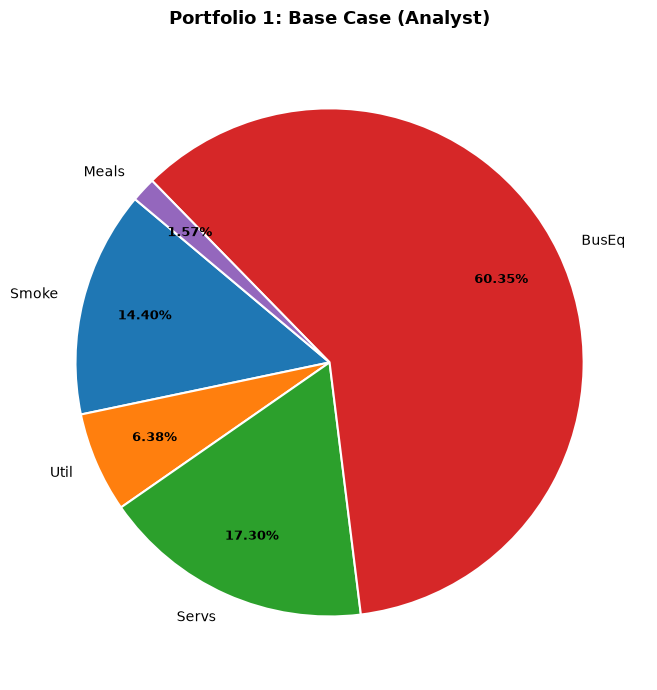

Saved figure to pie_chair_sharpe.png


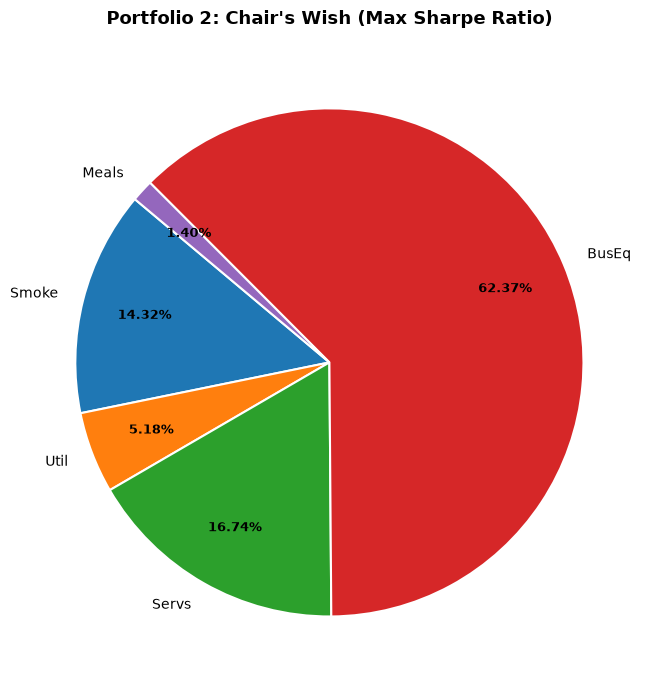

Saved figure to pie_risk_manager_cvar.png


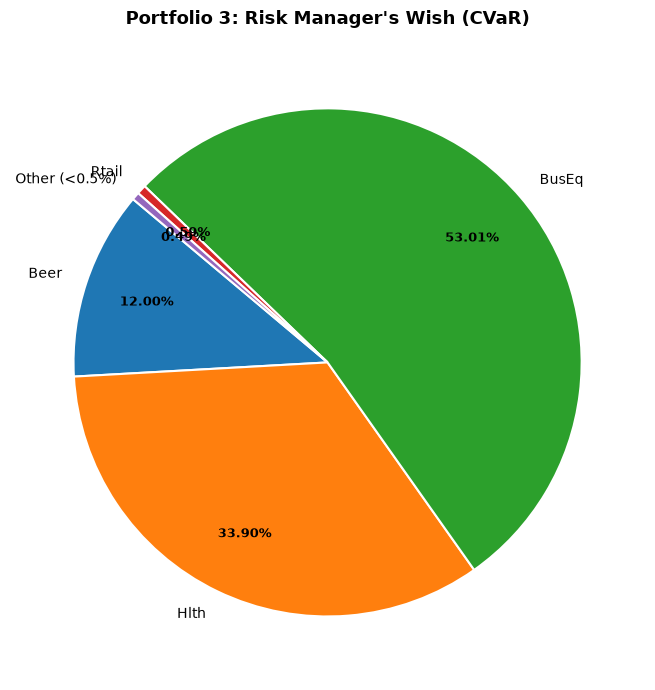

In [300]:
def plot_portfolio_pie(
    weights,
    asset_names,
    title,
    filename=None,
    threshold=0.005,
    colors_palette=None,
):
  """Plots a clean pie chart of portfolio weights above a given threshold.

  Near-zero weights are aggregated into 'Other' if any exist.
  """
  weights = np.asarray(weights).flatten()
  mask = weights > threshold

  filtered_weights = list(weights[mask])
  filtered_names = [asset_names[i] for i in range(len(weights)) if mask[i]]

  # If there is a small remainder of tiny weights, group them into 'Other (<0.5%)'
  remainder = 1.0 - sum(filtered_weights)
  if remainder > 1e-4:
    filtered_weights.append(remainder)
    filtered_names.append("Other (<0.5%)")

  plt.figure(figsize=(7, 7))
  wedges, texts, autotexts = plt.pie(
      filtered_weights,
      labels=filtered_names,
      autopct="%1.2f%%",
      startangle=140,
      pctdistance=0.75,
      colors=colors_palette,
      wedgeprops=dict(edgecolor="white", linewidth=1.5),
  )

  # Style percentages for clarity
  for autotext in autotexts:
    autotext.set_fontsize(9)
    autotext.set_weight("bold")

  plt.title(title, fontsize=13, weight="bold", pad=15)
  plt.tight_layout()

  if filename:
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    print(f"Saved figure to {filename}")
  plt.show()


# ------------------------------------------------------------------------------
# 1. Base Case Portfolio
# ------------------------------------------------------------------------------
plot_portfolio_pie(
    w_base,
    names,
    title="Portfolio 1: Base Case (Analyst)",
    filename="pie_base_case.png",
)

# ------------------------------------------------------------------------------
# 2. Chair's Wish: Maximized Sharpe Ratio
# ------------------------------------------------------------------------------
plot_portfolio_pie(
    w_sharpe,
    names,
    title="Portfolio 2: Chair's Wish (Max Sharpe Ratio)",
    filename="pie_chair_sharpe.png",
)

# ------------------------------------------------------------------------------
# 3. Risk Manager's Wish: CVaR
# ------------------------------------------------------------------------------
if w_cvar is not None:
  plot_portfolio_pie(
      w_cvar,
      names,
      title="Portfolio 3: Risk Manager's Wish (CVaR)",
      filename="pie_risk_manager_cvar.png",
  )

OSError: [Errno 22] Invalid argument: 'portfolios_comparison_pies.png'

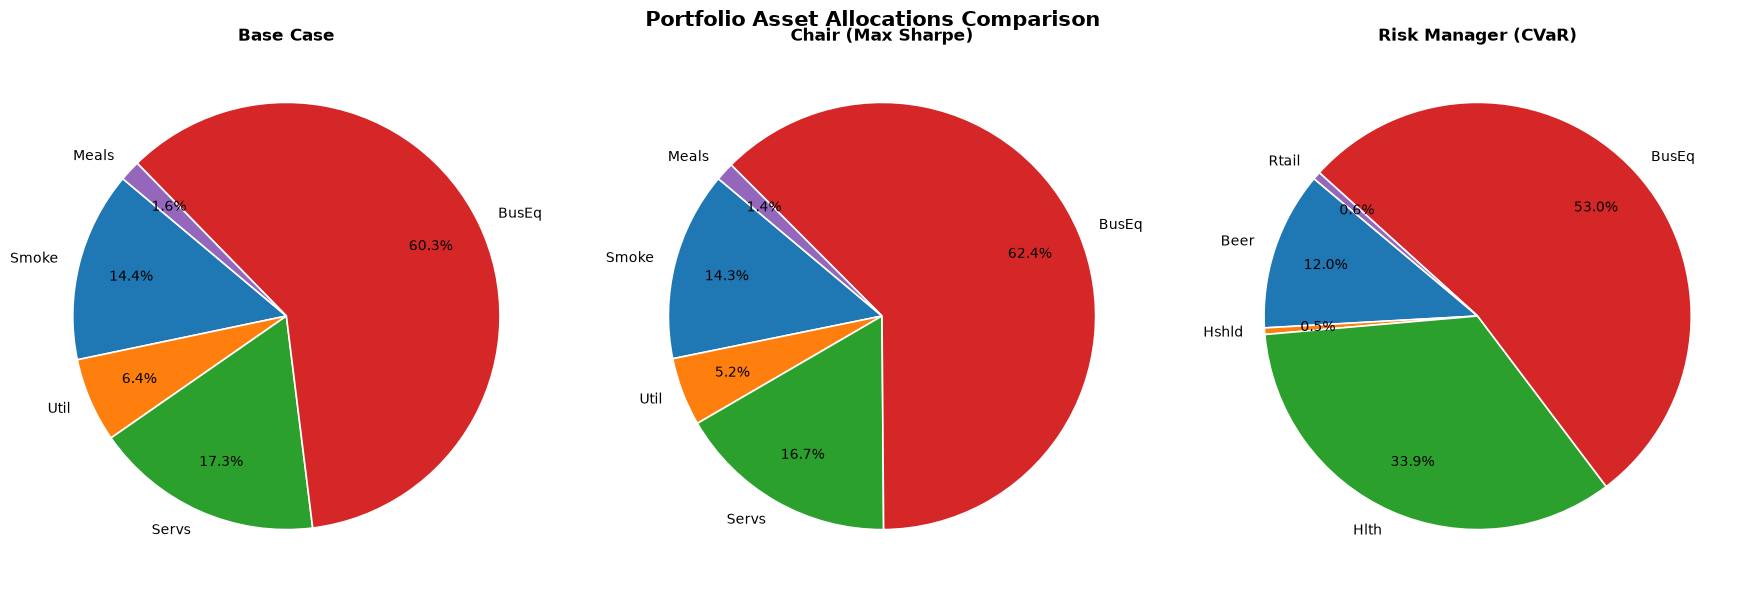

In [301]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

portfolios = [
    ("Base Case", w_base, axes[0]),
    ("Chair (Max Sharpe)", w_sharpe, axes[1]),
    ("Risk Manager (CVaR)", w_cvar, axes[2]),
]

threshold = 0.001

for title, w_vec, ax in portfolios:
  if w_vec is None:
    ax.text(
        0.5,
        0.5,
        "Infeasible / Failed",
        ha="center",
        va="center",
        fontsize=12,
        color="red",
    )
    ax.set_title(title, fontsize=12, weight="bold")
    ax.axis("off")
    continue

  w_arr = np.asarray(w_vec).flatten()
  mask = w_arr > threshold
  f_weights = list(w_arr[mask])
  f_names = [names[i] for i in range(len(w_arr)) if mask[i]]

  remainder = 1.0 - sum(f_weights)
  if remainder > 1e-4:
    f_weights.append(remainder)
    f_names.append("Other")

  ax.pie(
      f_weights,
      labels=f_names,
      autopct="%1.1f%%",
      startangle=140,
      pctdistance=0.75,
      wedgeprops=dict(edgecolor="white", linewidth=1.2),
  )
  ax.set_title(title, fontsize=12, weight="bold")

plt.suptitle("Portfolio Asset Allocations Comparison", fontsize=15, weight="bold")
plt.tight_layout()
plt.savefig("portfolios_comparison_pies.png", dpi=300, bbox_inches="tight")
plt.show()